# 01. Dataset overview and chunking inspection

Part of Step 6's seven-notebook series: [01](01_dataset_and_chunking.ipynb) dataset/chunking, [02](02_experiment_a_chunking_strategy.ipynb) Experiment A, [03](03_experiment_b_search_mode.ipynb) Experiment B, [04](04_experiment_c_embedding_model.ipynb) Experiment C, [05](05_experiment_d_weights_and_rrf.ipynb) Experiment D, [06](06_experiment_e_rerank.ipynb) Experiment E, [07](07_calibration_and_analysis.ipynb) calibration/PCA/latency/failure analysis/conclusions. Each runs standalone against its own fresh ingest (via `_setup.py`); none depends on another's kernel state.

Counts by role, seniority and file format from `data/resume_specs.json`, the
extraction accuracy `resume_metadata.extract_metadata` achieves on this
dataset, and an inspection of the default `section` chunking strategy.


In [1]:
import _setup as s
import matplotlib.pyplot as plt
import pandas as pd

W1031 11:09:22.919000 87717 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

## Dataset overview


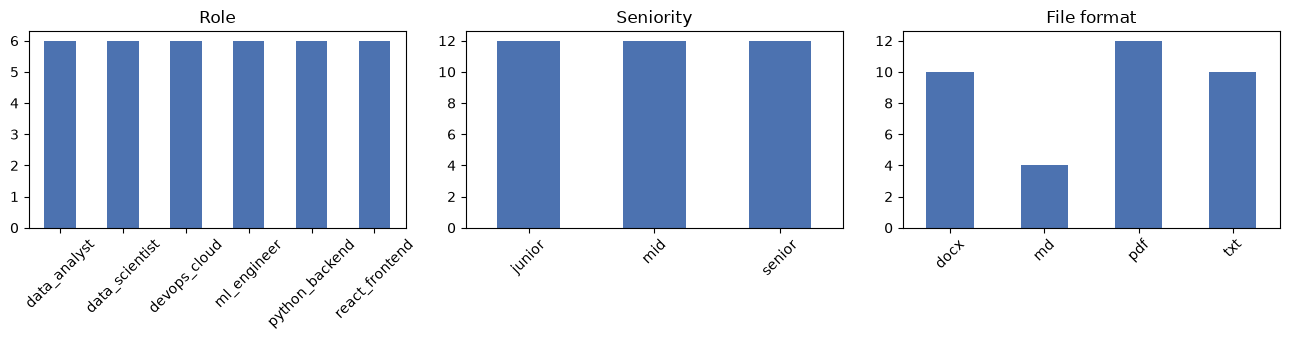

In [2]:
df_specs = pd.DataFrame(s.specs)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col, title in zip(
    axes, ["role", "seniority", "file_format"], ["Role", "Seniority", "File format"], strict=True
):
    df_specs[col].value_counts().sort_index().plot(kind="bar", ax=ax, color="#4C72B0")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [3]:
extraction = s.extraction_accuracy(s.candidates, s.specs_by_id)
pd.DataFrame([extraction]).T.rename(columns={0: "value"})

,value
n,36.000000
name_accuracy,1.000000
years_within_1yr_accuracy,0.944444
degree_accuracy,1.000000
skills_precision,0.890212
skills_recall,0.976025
skill_years_within_1yr_accuracy,0.625000


## Chunking inspection (default: `section`)


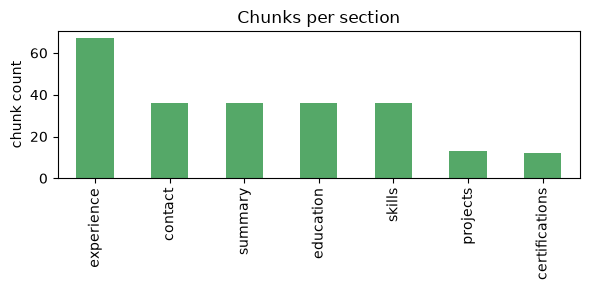

In [4]:
pd.Series(s.ingest_stats.chunk_counts).sort_values(ascending=False).plot(
    kind="bar", figsize=(6, 3), color="#55A868", title="Chunks per section"
)
plt.ylabel("chunk count")
plt.tight_layout()
plt.show()

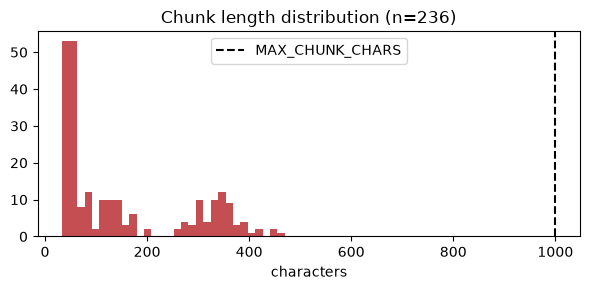

In [5]:
chunk_lengths = [len(chunk.text) for profile in s.candidates for chunk in profile.chunks]
plt.figure(figsize=(6, 3))
plt.hist(chunk_lengths, bins=30, color="#C44E52")
plt.axvline(s.config.MAX_CHUNK_CHARS, color="black", linestyle="--", label="MAX_CHUNK_CHARS")
plt.title(f"Chunk length distribution (n={len(chunk_lengths)})")
plt.xlabel("characters")
plt.legend()
plt.tight_layout()
plt.show()

In [6]:
sample = s.candidates[0]
print(f"{sample.name} ({sample.resume_path}): {len(sample.chunks)} chunks\n")
for chunk in sample.chunks[:3]:
    print(f"--- {chunk.chunk_id} ---")
    print(chunk.text[:300])
    print()

Amelia Chen (data/resumes/amelia_chen.pdf): 6 chunks

--- amelia_chen.pdf::contact::0 ---
Amelia Chen
amelia.chen@example.com | (415) 555-0134

--- amelia_chen.pdf::summary::0 ---
Data Scientist with 3+ years turning SQL and Python analysis into decisions, using Pandas and Scikit-learn to
model and explain customer behavior.

--- amelia_chen.pdf::experience::0 ---
Data Scientist, Pivotal Works
Jul 2024 - Present
- Built dashboards summarizing key metrics for the leadership team.
- Designed controlled experiments to compare product variants and measured the impact on conversion
before any change shipped broadly.
- Used Pandas and NumPy to clean and transform m

